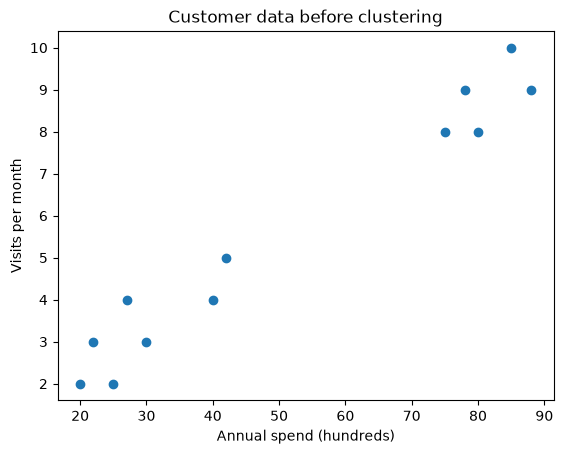

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

customers = pd.DataFrame({
    "AnnualSpend": [20,22,25,27,30,75,78,80,85,88,40,42],
    "VisitsPerMonth": [2,3,2,4,3,8,9,8,10,9,4,5]
})
plt.scatter(customers["AnnualSpend"],
            customers["VisitsPerMonth"])
plt.xlabel("Annual spend (hundreds)")
plt.ylabel("Visits per month")
plt.title("Customer data before clustering")
plt.show()

C:\Users\SHIVANI R\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


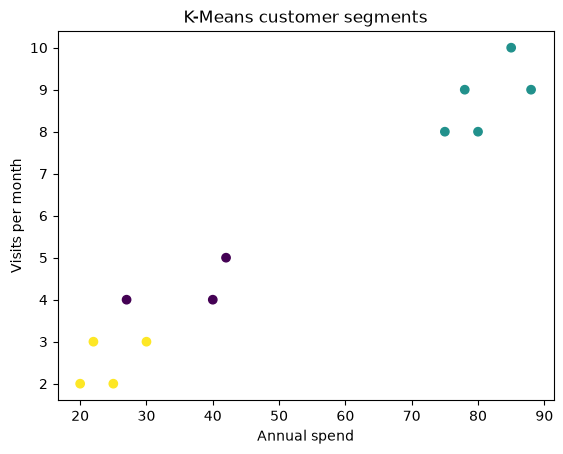

    AnnualSpend  VisitsPerMonth  Cluster
0            20               2        2
1            22               3        2
2            25               2        2
3            27               4        0
4            30               3        2
5            75               8        1
6            78               9        1
7            80               8        1
8            85              10        1
9            88               9        1
10           40               4        0
11           42               5        0


In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

scaler = StandardScaler()
X_scaled = scaler.fit_transform(customers)

km = KMeans(n_clusters=3, random_state=42, n_init=10)
customers["Cluster"] = km.fit_predict(X_scaled)

plt.scatter(customers["AnnualSpend"],
            customers["VisitsPerMonth"],
            c=customers["Cluster"])
plt.xlabel("Annual spend")
plt.ylabel("Visits per month")
plt.title("K-Means customer segments")
plt.show()
print(customers)

In [3]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

for k in range(2, 6):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    print(k,
          "inertia:", round(model.inertia_, 2),
          "silhouette:", round(silhouette_score(X_scaled, labels), 3))

2 inertia: 2.03 silhouette: 0.786
3 inertia: 0.97 silhouette: 0.591
4 inertia: 0.66 silhouette: 0.449
5 inertia: 0.38 silhouette: 0.4


C:\Users\SHIVANI R\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\SHIVANI R\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\SHIVANI R\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\SHIVANI R\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memor

Cluster labels: [0 0 0 0 0 1 1 1 1 1 0 0]
Noise points: 0


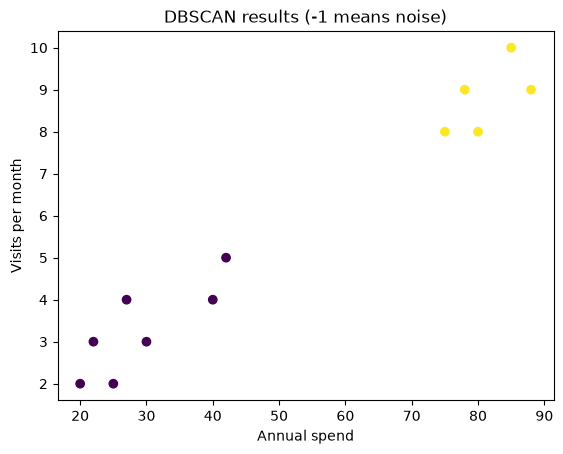

In [4]:
from sklearn.cluster import DBSCAN

db = DBSCAN(eps=0.8, min_samples=2)
db_labels = db.fit_predict(X_scaled)

print("Cluster labels:", db_labels)
print("Noise points:", sum(db_labels == -1))

plt.scatter(customers["AnnualSpend"],
            customers["VisitsPerMonth"],
            c=db_labels)
plt.xlabel("Annual spend")
plt.ylabel("Visits per month")
plt.title("DBSCAN results (-1 means noise)")
plt.show()

Explained variance: [0.73  0.229]


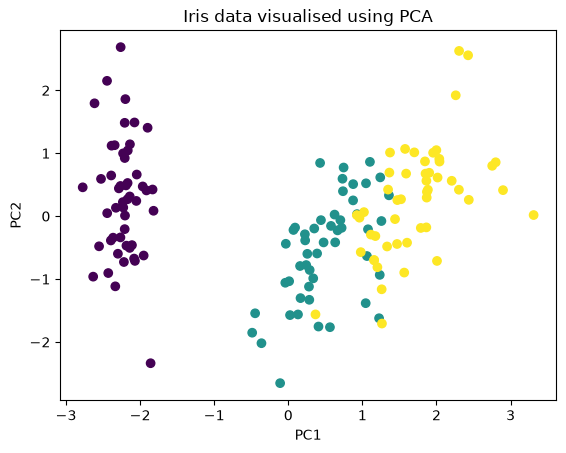

In [5]:
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

iris = load_iris()
X_iris = StandardScaler().fit_transform(iris.data)

pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_iris)

print("Explained variance:",
      pca.explained_variance_ratio_.round(3))
plt.scatter(X_2d[:,0], X_2d[:,1], c=iris.target)
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("Iris data visualised using PCA")
plt.show()

In [6]:
from sklearn.ensemble import IsolationForest
import numpy as np

transactions = np.array([
    [20, 2], [22, 3], [18, 2], [25, 3],
    [21, 2], [23, 4], [19, 3], [250, 20]
])

detector = IsolationForest(contamination=0.12, random_state=42)
labels = detector.fit_predict(transactions)

for row, label in zip(transactions, labels):
    print(row, "Anomaly" if label == -1 else "Normal")

[20  2] Normal
[22  3] Normal
[18  2] Normal
[25  3] Normal
[21  2] Normal
[23  4] Normal
[19  3] Normal
[250  20] Anomaly


Libraries imported successfully
    AnnualSpend  VisitsPerMonth
0            20               2
1            22               3
2            25               2
3            27               4
4            30               3
5            75               8
6            78               9
7            80               8
8            85              10
9            88               9
10           40               4
11           42               5


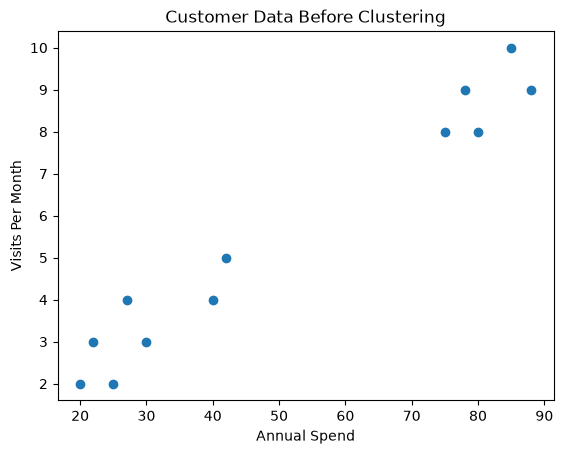

Data scaled successfully
[[-1.17392805 -1.24808193]
 [-1.09819076 -0.89978   ]
 [-0.98458482 -1.24808193]
 [-0.90884753 -0.55147806]
 [-0.79524158 -0.89978   ]
 [ 0.90884753  0.84172968]
 [ 1.02245347  1.19003161]
 [ 1.09819076  0.84172968]
 [ 1.28753399  1.53833354]
 [ 1.40113993  1.19003161]
 [-0.41655512 -0.55147806]
 [-0.34081782 -0.20317613]]
Cluster labels: [0 0 0 0 0 1 1 1 1 1 0 0]
Noise points: 0


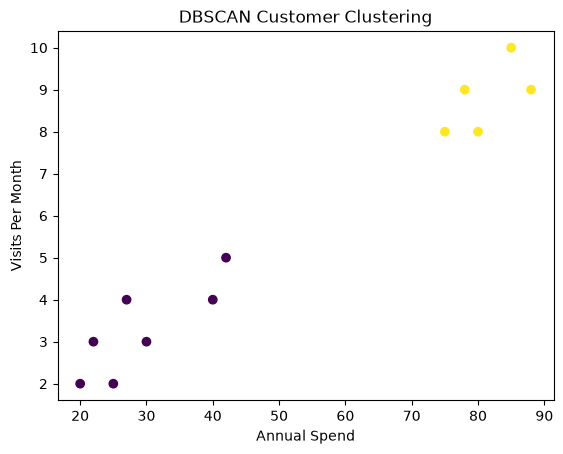

    AnnualSpend  VisitsPerMonth  Cluster
0            20               2        0
1            22               3        0
2            25               2        0
3            27               4        0
4            30               3        0
5            75               8        1
6            78               9        1
7            80               8        1
8            85              10        1
9            88               9        1
10           40               4        0
11           42               5        0
New cluster labels: [ 0 -1  0 -1 -1  1 -1  1 -1 -1 -1 -1]
Noise points: 8


In [8]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

print("Libraries imported successfully")
customers = pd.DataFrame({
    "AnnualSpend": [20, 22, 25, 27, 30, 75, 78, 80, 85, 88, 40, 42],
    "VisitsPerMonth": [2, 3, 2, 4, 3, 8, 9, 8, 10, 9, 4, 5]
})

print(customers)
plt.scatter(customers["AnnualSpend"], customers["VisitsPerMonth"])

plt.xlabel("Annual Spend")
plt.ylabel("Visits Per Month")
plt.title("Customer Data Before Clustering")

plt.show()
scaler = StandardScaler()

X_scaled = scaler.fit_transform(customers)

print("Data scaled successfully")
print(X_scaled)
db = DBSCAN(eps=0.8, min_samples=2)

db_labels = db.fit_predict(X_scaled)

print("Cluster labels:", db_labels)
print("Noise points:", sum(db_labels == -1))
plt.scatter(
    customers["AnnualSpend"],
    customers["VisitsPerMonth"],
    c=db_labels
)

plt.xlabel("Annual Spend")
plt.ylabel("Visits Per Month")
plt.title("DBSCAN Customer Clustering")

plt.show()
customers["Cluster"] = db_labels

print(customers)
db_test = DBSCAN(eps=0.2, min_samples=2)

test_labels = db_test.fit_predict(X_scaled)

print("New cluster labels:", test_labels)
print("Noise points:", sum(test_labels == -1))